# Ringkasan Data
* **survived** : status keberlangsungan hidup (selamat/tidak selamat)
* **pclass** : kelas tiket penumpang
* **sex** : jenis kelamin
* **age** : usia
* **sibsp** : jumlah saudara kandung atau pasangan di kapal
* **parch** : jumlah orang tua atau anak di kapal
* **fare** : tarif tiket penumpang
* **embarked** : pelabuhan tempat penumpang naik
* **class** : nama kelas tiket (First, Second, Third)
* **who** : kategori penumpang berdasarkan jenis kelamin dan usia
* **adult_male** : apakah penumpang laki-laki dewasa?
* **deck** : dek tempat penumpang tinggal
* **embark_town** : nama kota tempat penumpang naik
* **alive** : status kelangsungan hidup dalam bentuk teks (yes atau no)
* **alone** : apakah penumpang bepergian sendirian?

## Tujuan
* Menganalisis Faktor yang Mempengaruhi Kelangsungan Hidup
Mengidentifikasi variabel-variabel (seperti kelas tiket, jenis kelamin, usia, atau pelabuhan embarkasi) yang memiliki pengaruh signifikan terhadap peluang selamat.
* Eksplorasi Distribusi Data Penumpang
Melihat distribusi usia penumpang berdasarkan kategori tertentu.

In [1]:
import seaborn as sns

# Load dataset
data = sns.load_dataset('titanic')
data

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


## Explorasi Data Analysis (EDA)
Explorasi data untuk memahami pola.

In [2]:
data.describe() # show statistics summary

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [3]:
# check missing values
data.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


### Visualisasi

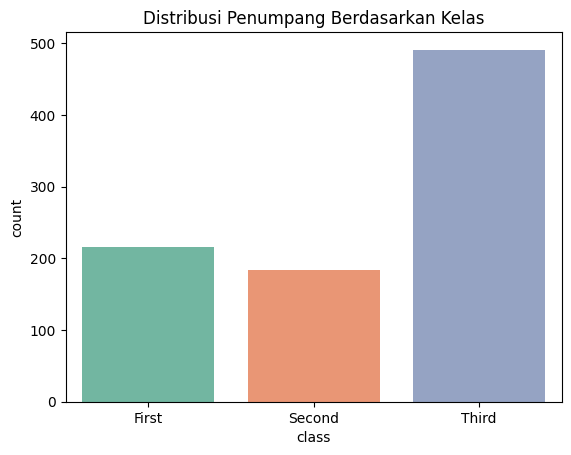

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x='class', hue='class', data=data, palette='Set2', legend=False)
plt.title('Distribusi Penumpang Berdasarkan Kelas')
plt.show()

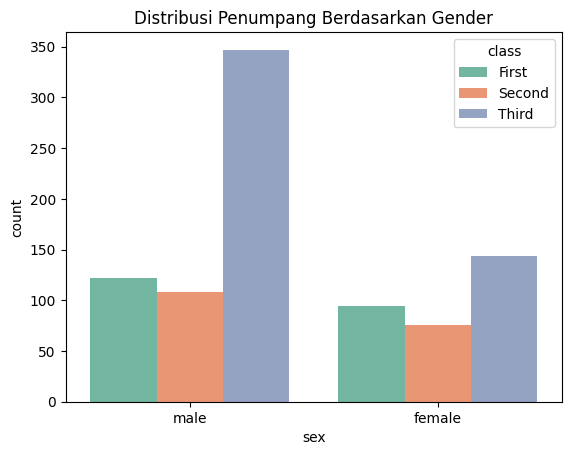

In [5]:
sns.countplot(x='sex', hue='class', palette='Set2', data=data)
plt.title('Distribusi Penumpang Berdasarkan Gender')
plt.show()

## Data Cleaning
Pada tahap ini akan dilakukan pembersihan data agar mempermudah proses analisis dan penarikan kesimpulan.

In [6]:
print(data[['age', 'deck', 'embarked', 'embark_town']].isnull().sum())

age            177
deck           688
embarked         2
embark_town      2
dtype: int64


In [7]:
data['age'] = data['age'].fillna(data['age'].mean()) # use the mean for numerical columns.
data['embarked'] = data['embarked'].fillna(data['embarked'].mode()[0]) # use the mode for categorical columns

In [8]:
# re-check
print(data[['age', 'deck', 'embarked', 'embark_town']].isnull().sum())

age              0
deck           688
embarked         0
embark_town      2
dtype: int64


Terlihat bahwa missing values pada kolom age dan embarked sudah tidak ada, tetapi pada kolom deck dan embark_town masih ada, pada proses selanjutnya ada beberapa kolom yang akan di hapus termasuk kolom tersebut, karena tidak terlalu di butuhkan dalam proses analisis.

In [9]:
columns_to_drop = ['deck', 'embark_town', 'who', 'parch', 'alive', 'adult_male'] # remove cols

In [10]:
import pandas as pd

data = data.drop(columns=columns_to_drop)
pd.set_option('display.max_columns', None)  # show all columns

data

,survived,pclass,sex,age,sibsp,fare,embarked,class,alone
0,0,3,male,22.000000,1,7.2500,S,Third,False
1,1,1,female,38.000000,1,71.2833,C,First,False
2,1,3,female,26.000000,0,7.9250,S,Third,True
3,1,1,female,35.000000,1,53.1000,S,First,False
4,0,3,male,35.000000,0,8.0500,S,Third,True
...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.000000,0,13.0000,S,Second,True
887,1,1,female,19.000000,0,30.0000,S,First,True
888,0,3,female,29.699118,1,23.4500,S,Third,False
889,1,1,male,26.000000,0,30.0000,C,First,True


In [11]:
data['age'] = data['age'].round()

invalid_ages = data[(data['age'] < 0) | (data['age'] > 100)]
print("Nilai Usia Tidak Valid:")
print(invalid_ages)

Nilai Usia Tidak Valid:
Empty DataFrame
Columns: [survived, pclass, sex, age, sibsp, fare, embarked, class, alone]
Index: []


## Feature Engineering

In [12]:
from sklearn.preprocessing import LabelEncoder

columns_to_encode = {
    'LabelEncoding': ['sex', 'class', 'alone'],  # Label-encoded columns
    'OneHotEncoding': ['embarked']  # OHE-encoded columns
}

label_encoder = LabelEncoder()
for col in columns_to_encode['LabelEncoding']:
    data[col] = label_encoder.fit_transform(data[col])

for col in columns_to_encode['OneHotEncoding']:
    one_hot = pd.get_dummies(data[col], prefix=col)
    data = pd.concat([data, one_hot], axis=1)
    data.drop(columns=[col], inplace=True)

data

,survived,pclass,sex,age,sibsp,fare,class,alone,embarked_C,embarked_Q,embarked_S
0,0,3,1,22.0,1,7.2500,2,0,False,False,True
1,1,1,0,38.0,1,71.2833,0,0,True,False,False
2,1,3,0,26.0,0,7.9250,2,1,False,False,True
3,1,1,0,35.0,1,53.1000,0,0,False,False,True
4,0,3,1,35.0,0,8.0500,2,1,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,1,27.0,0,13.0000,1,1,False,False,True
887,1,1,0,19.0,0,30.0000,0,1,False,False,True
888,0,3,0,30.0,1,23.4500,2,0,False,False,True
889,1,1,1,26.0,0,30.0000,0,1,True,False,False


In [13]:
boolean_encoded_columns = ['embarked_C', 'embarked_Q', 'embarked_S']  # OHE result column
for col in boolean_encoded_columns:
    data[col] = data[col].astype(int)

data

,survived,pclass,sex,age,sibsp,fare,class,alone,embarked_C,embarked_Q,embarked_S
0,0,3,1,22.0,1,7.2500,2,0,0,0,1
1,1,1,0,38.0,1,71.2833,0,0,1,0,0
2,1,3,0,26.0,0,7.9250,2,1,0,0,1
3,1,1,0,35.0,1,53.1000,0,0,0,0,1
4,0,3,1,35.0,0,8.0500,2,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,1,27.0,0,13.0000,1,1,0,0,1
887,1,1,0,19.0,0,30.0000,0,1,0,0,1
888,0,3,0,30.0,1,23.4500,2,0,0,0,1
889,1,1,1,26.0,0,30.0000,0,1,1,0,0


### Handle Outlier
Outlier adalah nilai yang jauh berbeda dari sebagian besar data lainnya dalam suatu dataset. Dalam analisis data, mengidentifikasi dan menangani outlier penting karena outlier dapat mempengaruhi model dan hasil analisis, seperti merusak statistik deskriptif atau membuat model lebih sensitif terhadap fluktuasi kecil.

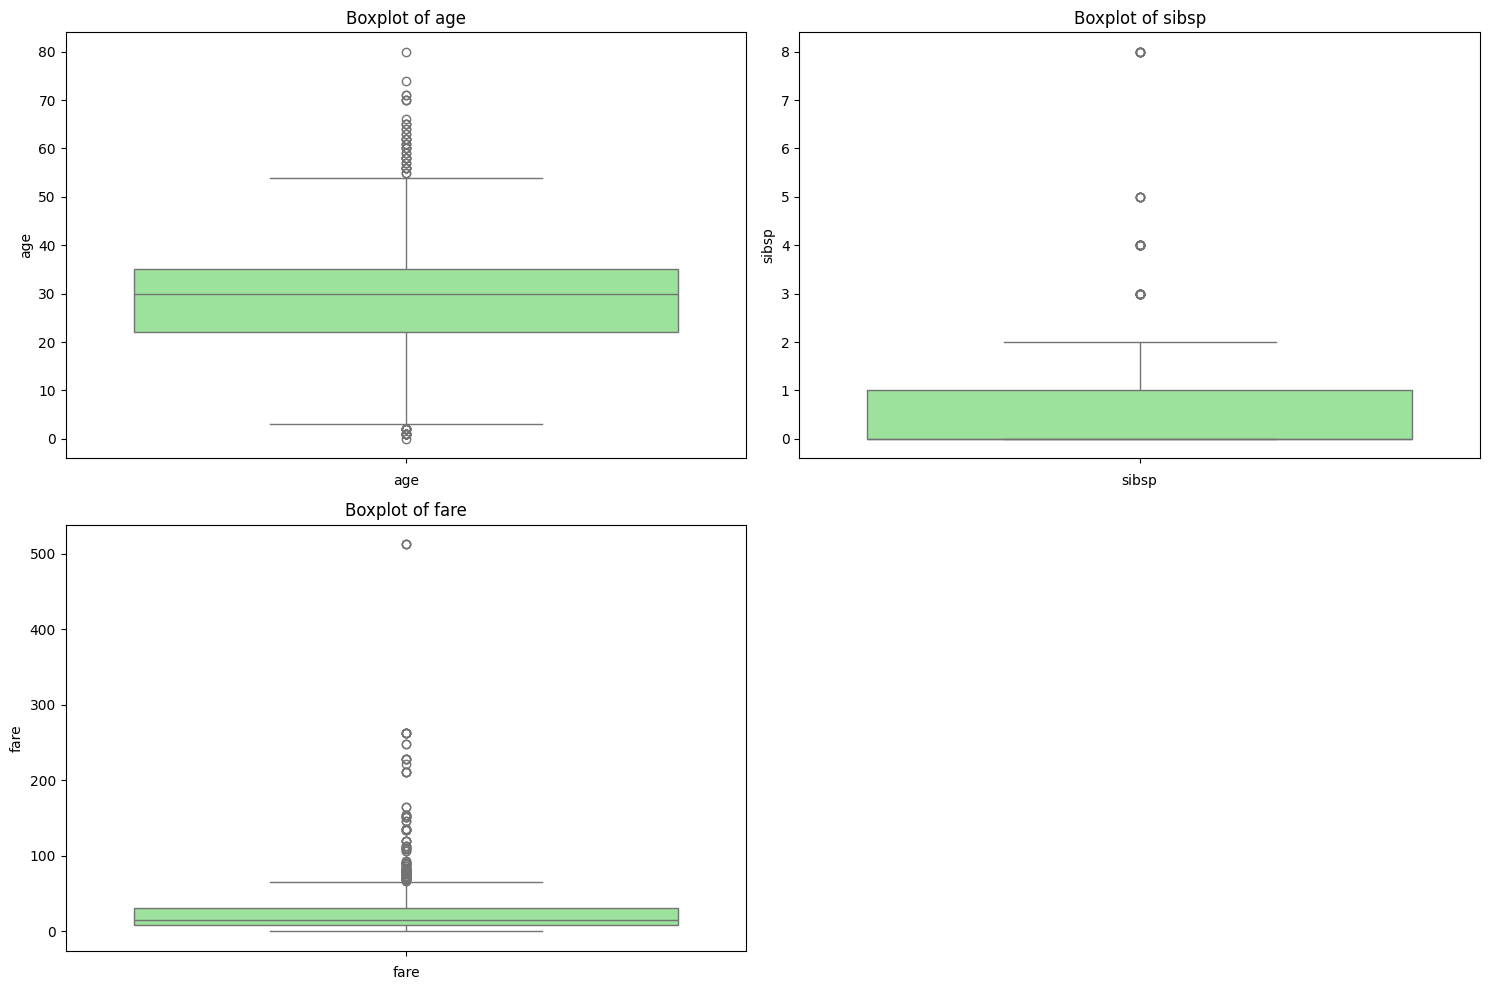

In [14]:
def plot_boxplots(df, columns):
    plt.figure(figsize=(15, 10))
    for i, col in enumerate(columns, 1):
        plt.subplot(2, 2, i)
        sns.boxplot(df[col], color='lightgreen')
        plt.title(f'Boxplot of {col}')
        plt.xlabel(col)
    plt.tight_layout()
    plt.show()

numeric_columns = ['age', 'sibsp', 'fare']
plot_boxplots(data, numeric_columns)

pada visualisasi plot tersebut terlihat ada outlier di setiap kolom nya, kita akan menghandle nya dengan metode capping.

Metode capping adalah teknik yang digunakan untuk menangani outlier dalam data dengan cara membatasi (atau “memotong”) nilai-nilai ekstrem agar berada dalam rentang tertentu yang wajar.

In [15]:
def handle_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    # Replace outlier values ​​with the lower/upper bound
    data[column] = data[column].clip(lower=lower_bound, upper=upper_bound)

# Apply capping to each numerical column
for col in numeric_columns:
    handle_outliers(data, col)

# Check results after handling outliers
data[numeric_columns].describe()

,age,sibsp,fare
count,891.000000,891.000000,891.000000
mean,29.430976,0.426487,24.046813
std,12.065086,0.708246,20.481625
min,2.500000,0.000000,0.000000
25%,22.000000,0.000000,7.910400
50%,30.000000,0.000000,14.454200
75%,35.000000,1.000000,31.000000
max,54.500000,2.500000,65.634400


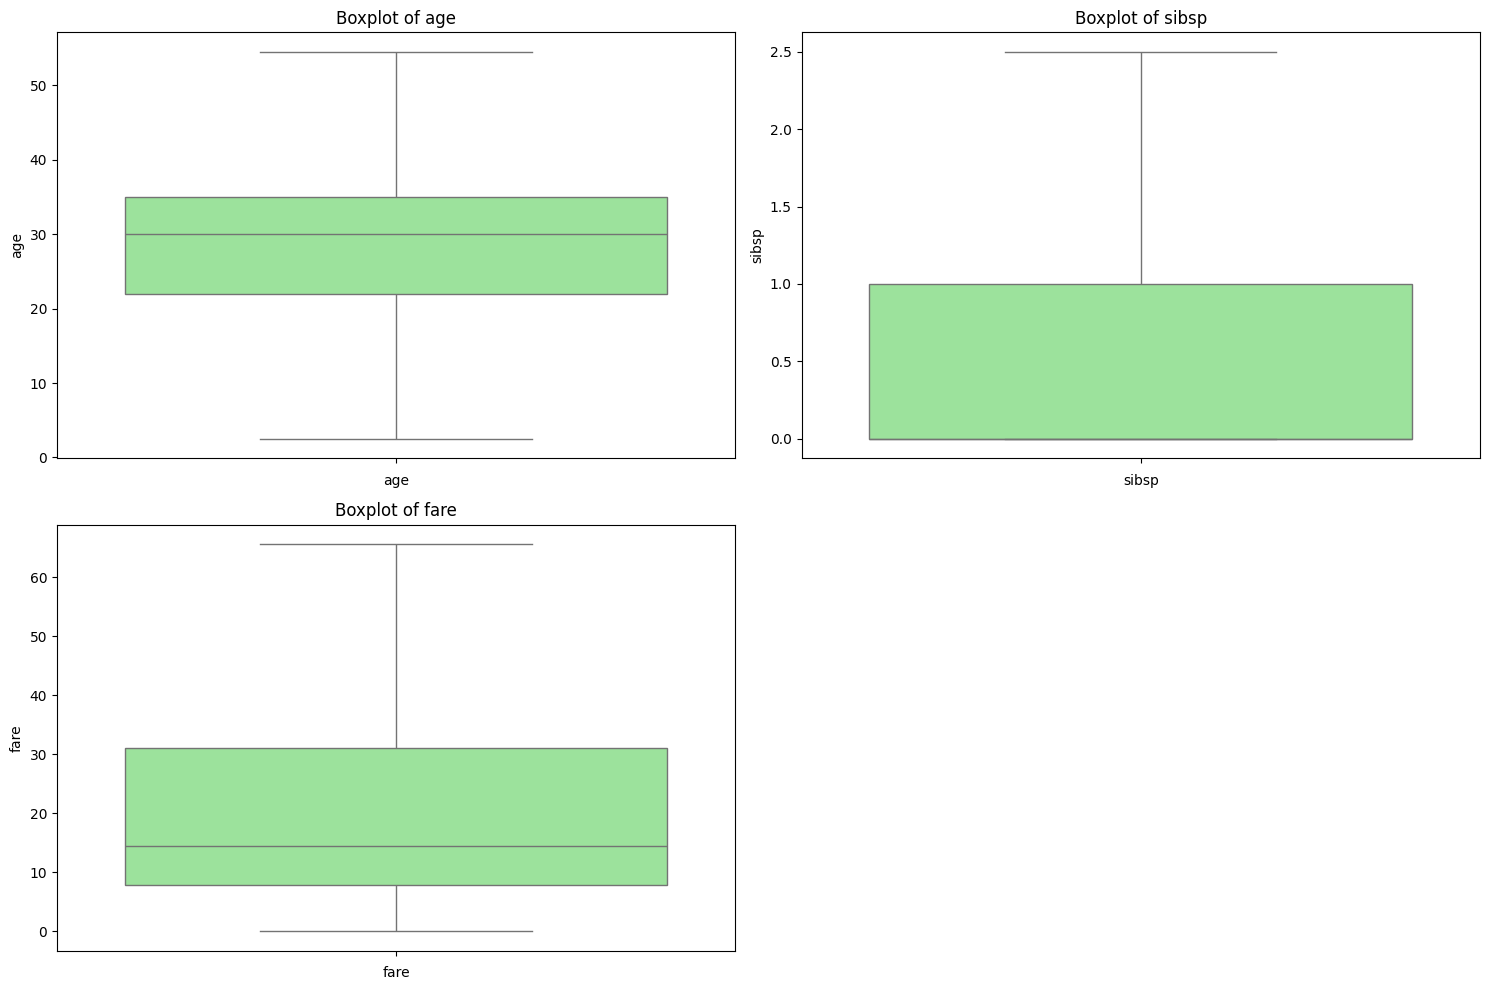

In [16]:
# re-check
numeric_columns = ['age', 'sibsp', 'fare']
plot_boxplots(data, numeric_columns)

### Cek Korelasi

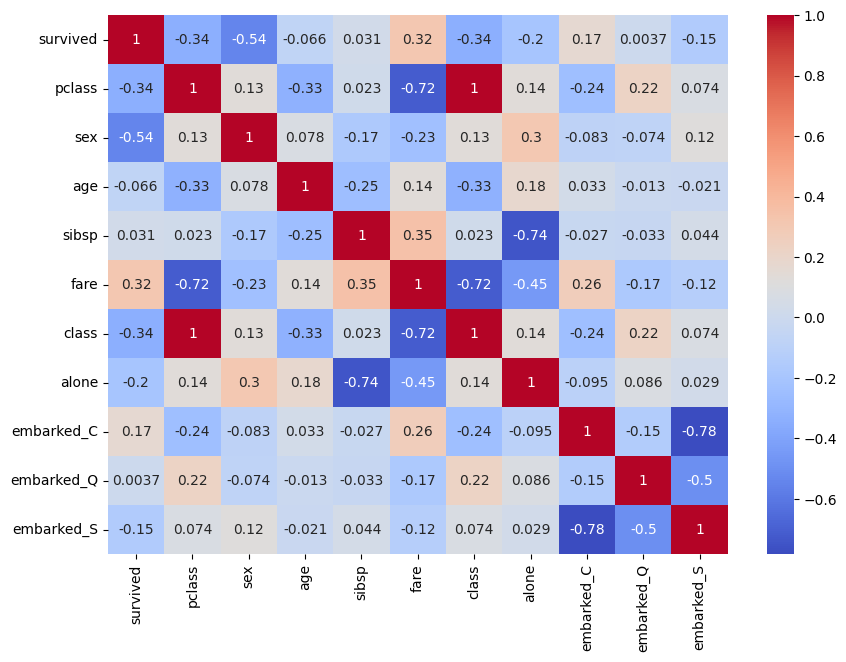

In [17]:
plt.figure(figsize=(10, 7))

sns.heatmap(data.corr(), annot=True, cmap='coolwarm')
plt.show()

Heatmap memungkinkan kita untuk melihat hubungan linear antara fitur. Korelasi positif (nilai dekat +1) menunjukkan bahwa dua fitur bergerak searah, sementara korelasi negatif (nilai dekat -1) menunjukkan bahwa dua fitur bergerak berlawanan arah. Korelasi mendekati 0 menunjukkan bahwa tidak ada hubungan linier yang signifikan antara fitur tersebut.

In [18]:
correlation_matrix = data.corr()

print("Korelasi Antar Fitur:")
print(correlation_matrix.to_string())

Korelasi Antar Fitur:
            survived    pclass       sex       age     sibsp      fare     class     alone  embarked_C  embarked_Q  embarked_S
survived    1.000000 -0.338481 -0.543351 -0.066487  0.031434  0.317430 -0.338481 -0.203367    0.168240    0.003650   -0.149683
pclass     -0.338481  1.000000  0.131900 -0.329486  0.023180 -0.715300  1.000000  0.135207   -0.243292    0.221009    0.074053
sex        -0.543351  0.131900  1.000000  0.078386 -0.167885 -0.234969  0.131900  0.303646   -0.082853   -0.074115    0.119224
age        -0.066487 -0.329486  0.078386  1.000000 -0.252005  0.136460 -0.329486  0.181374    0.033217   -0.012980   -0.020931
sibsp       0.031434  0.023180 -0.167885 -0.252005  1.000000  0.349615  0.023180 -0.742081   -0.026955   -0.032952    0.044351
fare        0.317430 -0.715300 -0.234969  0.136460  0.349615  1.000000 -0.715300 -0.454231    0.263603   -0.171339   -0.123104
class      -0.338481  1.000000  0.131900 -0.329486  0.023180 -0.715300  1.000000  0.13520

### Cek Distribusi Normal

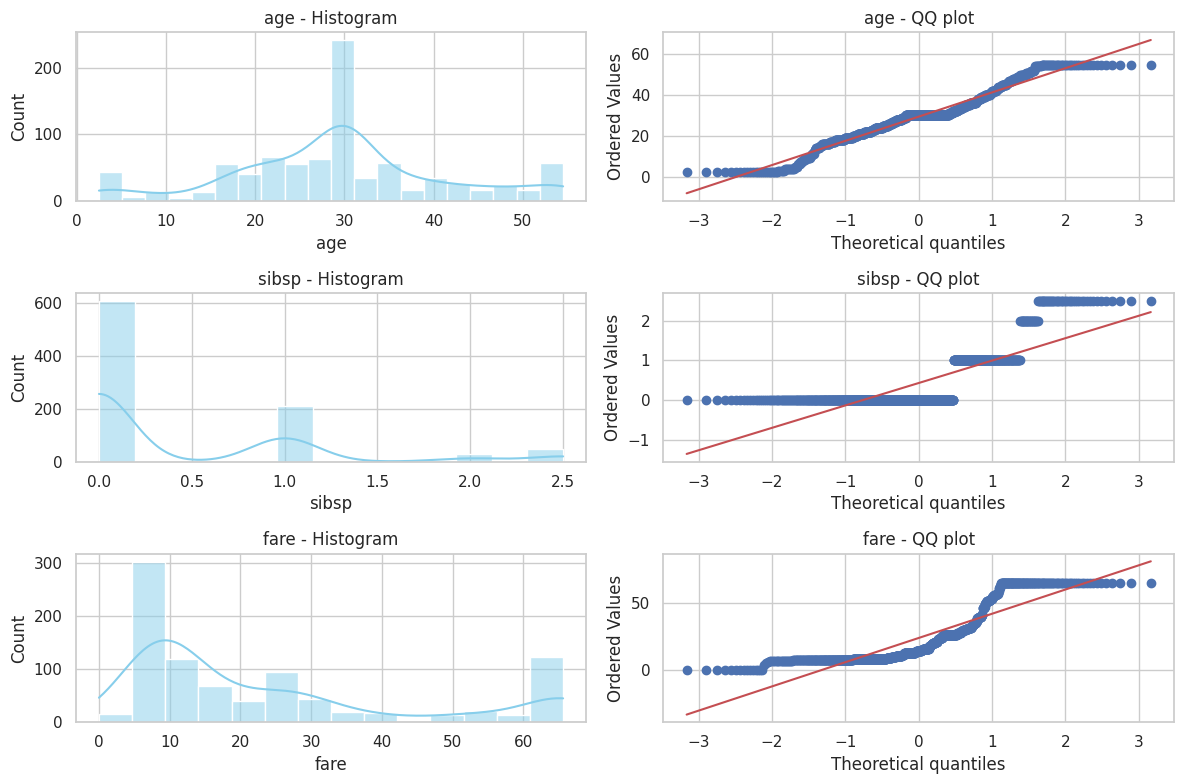

In [19]:
import scipy.stats as stats

sns.set(style="whitegrid")

# Creating a figure and axes for subplots
fig, axes = plt.subplots(len(numeric_columns), 2, figsize=(12, 8))

# Loop for each numeric column
for i, col in enumerate(numeric_columns):
    # Plot histogram
    sns.histplot(data[col], kde=True, ax=axes[i, 0], color='skyblue')
    axes[i, 0].set_title(f'{col} - Histogram')

    # Use QQ plot
    stats.probplot(data[col].dropna(), dist="norm", plot=axes[i, 1])
    axes[i, 1].set_title(f'{col} - QQ plot')

plt.tight_layout()
plt.show()

sepertinya kolom age memenuhi syarat distribusi normal, tetapi belum diketahui nilai dari statistik uji nya, untuk itu kita munculkan nilai statistik uji nya dengan syarat p-value sebesar 5%

In [20]:
for col in numeric_columns:
    stat, p_value = stats.shapiro(data[col])

    print(f'Kolom: {col}')
    print(f'Statistik Uji: {stat}')
    print(f'P-Value: {p_value}')

    # Checking whether data is normally distributed based on the p-value
    if p_value > 0.05:
        print("Data terdistribusi normal (gagal menolak hipotesis nol)\n")
    else:
        print("Data tidak terdistribusi normal (menolak hipotesis nol)\n")

Kolom: age
Statistik Uji: 0.960345426982475
P-Value: 8.238776849898012e-15
Data tidak terdistribusi normal (menolak hipotesis nol)

Kolom: sibsp
Statistik Uji: 0.6309308438776318
P-Value: 6.221107502945339e-40
Data tidak terdistribusi normal (menolak hipotesis nol)

Kolom: fare
Statistik Uji: 0.7871002019822306
P-Value: 1.5814679622164813e-32
Data tidak terdistribusi normal (menolak hipotesis nol)



# Kesimpulan
* Fitur-fitur seperti age, fare, sibsp, dan pclass memiliki variabilitas yang cukup tinggi, yang menunjukkan adanya perbedaan yang signifikan antara individu dalam data.
* Korelasi antar fitur menunjukkan hubungan yang menarik, seperti antara pclass dan fare yang sangat negatif, mencerminkan kelas tiket yang lebih kecil (kelas 1) memiliki tarif lebih mahal.
* Korelasi negatif juga terlihat antara survived dan alone, yang menunjukkan bahwa penumpang yang sendirian atau tidak berkelompok cenderung tidak selamat.
* Variabel survied dan fare menunjukkan hubungan moderat dengan kelangsungan hidup, dimana penumpang yang membayar tarif lebih mahal cenderung memiliki peluang lebih besar untuk selamat.
* Korelasi antara age dan pclass menunjukkan bahwa penumpang yang lebih tua lebih cenderung membeli tiket kelas lebih rendah dibandingkan dengan penumpang yang lebih muda.



---



## 3D Plot

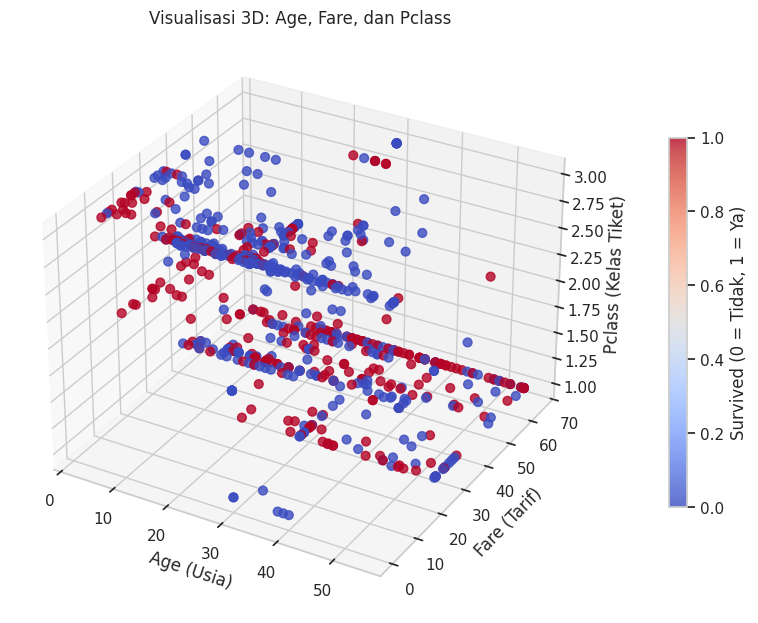

In [21]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    data['age'],
    data['fare'],
    data['pclass'],
    c=data['survived'],
    cmap='coolwarm',
    s=40,
    alpha=0.8
)

ax.set_xlabel('Age (Usia)')
ax.set_ylabel('Fare (Tarif)')
ax.set_zlabel('Pclass (Kelas Tiket)')
ax.set_title('Visualisasi 3D: Age, Fare, dan Pclass')

cbar = fig.colorbar(scatter, ax=ax, pad=0.1, shrink=0.6)
cbar.set_label('Survived (0 = Tidak, 1 = Ya)')

plt.show()